# Predicting experimental treatment effects
## Ashokkumar archive


### How Ashokkumar et al. made the predictions

- Each prompt combined a study introduction, a demographic profile, the experimental stimulus, and the outcome question with its response scale. The profiles described age, gender, race, education, ideology and party affiliation. The model was asked to predict the described person's response.
- For each condition and outcome in the primary archive, the authors used **120 prompts**. They sampled **five model responses per prompt and averaged those five responses**.
- They then averaged across prompts, using population weights to account for oversampled demographic groups. Differences between the weighted condition means gave predicted treatment effects. Our files use their GPT-4 predictions.

Source: Ashokkumar et al., main article and Methods, “LLM prompting”; Supplementary Information, “LLM prompting” and analysis of the primary archive. [Paper and supplement](https://doi.org/10.1038/s41586-026-10742-x) · [Replication archive](https://codeocean.com/capsule/9843791/tree/v1).


### The example in this notebook

Does information about racial discrimination change perceptions of discrimination and support for pro-Black policies? Can an LLM predict those changes?

Our example is **Beliefs about Racial Discrimination and Support for Pro-Black Policies**, by Ingar Haaland and Christopher Roth, published in *The Review of Economics and Statistics* 105(1), 40–53 (2023). The study description follows their accepted manuscript, Section II, and their original outcome definitions. [Published paper](https://doi.org/10.1162/rest_a_01036) · [Open accepted manuscript](https://wrap.warwick.ac.uk/id/eprint/151133/).

The human responses and GPT-4 simulations come from the [Ashokkumar et al. replication archive](https://codeocean.com/capsule/9843791/tree/v1), study `Haaland874`. We use existing predictions. No model account or coding agent is required.

Open this notebook inside the downloaded repository. The data and predictions are included; follow the setup instructions in the repository README.

## Before you run the analysis

Complete the setup in the repository README first. Run the following cell only if you need to install the analysis packages in this notebook’s Python environment. The first installation needs an internet connection. Then run the analysis cells in order.

In [ ]:
%pip install -q numpy pandas matplotlib openpyxl https://github.com/Michael-Howes/ppi_py/archive/2dc0ceede320ddf81b4d1050df04fbd1f48bd31b.zip

## 1. The information treatment

Participants read about a study of racial discrimination in hiring. The researchers sent equivalent resumes with white-sounding or Black-sounding names. Everyone learns that resumes with white-sounding names needed ten applications, on average, to receive one callback. Participants then estimate the corresponding number for Black-sounding names.

- The **information treatment** reveals that Black-sounding names needed fifteen applications per callback. It explains that employers were 50 percent more likely to call back applicants with white-sounding names.
- The **control group** proceeds to the outcome questions without receiving that result.

We ask whether the model captures treatment effects on perceptions and self-reported policy views.

| Archive outcome | Meaning | Scale |
|---|---|---|
| Racial Discrimination perception | Perceived seriousness of racial discrimination against Black people in the labor market | 1, not a problem at all, to 5, a very serious problem |
| Affirmative action: Preference | Support for giving qualified Black candidates preference over equally qualified white candidates in getting a job | 1, strongly oppose, to 5, strongly support |
| Affirmative action: Assistance | Support for giving qualified Black candidates assistance in getting a job | 1, strongly oppose, to 5, strongly support |

Haaland and Roth measured these three outcomes separately. We use the same three measures here. The original paper also includes incentivized beliefs, donations and other outcomes. Those are not all available as human/model outcome pairs here. In particular, perceived seriousness is not the paper's quantitative belief-updating measure or a verified manipulation check.

## Load the workshop data

Give `pd.read_csv` the **CSV filename**, not a study title or PDF name. `haaland_responses.csv` is our prepared workshop extract; it is not an original archive filename. It contains three outcomes from `Haaland874`. To change outcomes, use the outcome choice below.

The archive-wide response file contains other studies in one table. Later you can select them using the `study` and `outcome` columns. `effects.csv`, retained as an optional resource, is a renamed copy of the authors’ published `fig1_panelA.csv`.

Keep the repository folders together. The next cell finds the included files automatically when you open the notebook from the repository root or its `notebooks/` folder.

In [26]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ppi_py import classical_ols_ci, ppi_ols_ci
import sys

%matplotlib inline

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = str(ROOT / "data/workshop/ashokkumar") + "/"
sys.path.insert(0, str(ROOT / "scripts"))
from workshop_helpers import ppi_correlation, effective_sample_size
SEED = 20261013

data = pd.read_csv(DATA + "haaland_responses.csv")
print(data.groupby("outcome").size())
data.head()

outcome
Affirmative action: Assistance      1529
Affirmative action: Preference      1532
Racial Discrimination perception    1534
dtype: int64


,outcome,source_row,treated,Y,Yhat
0,Racial Discrimination perception,1,1,2.0,1.295182
1,Racial Discrimination perception,2,1,4.0,1.295182
2,Racial Discrimination perception,3,1,1.0,1.713471
3,Racial Discrimination perception,4,1,1.0,1.295182
4,Racial Discrimination perception,5,1,3.0,1.713471


## 2. Human responses and model predictions

We compare the average response in the treatment group with the average response in the control group. We do not estimate separate treatment effects for demographic subgroups.

The prepared file contains each person's response (`Y`) and a model prediction (`Yhat`). For this PPI illustration, we assigned predictions using the person's party affiliation and treatment condition. This is a workshop addition to Ashokkumar et al.’s analysis, which compares averages across conditions.

The preparation is already done. Choose an outcome below and run the analysis. [Data preparation details](../data/workshop/ashokkumar/README.md).


In [27]:
outcome = "Affirmative action: Assistance"  # Strongest PPI correlation among the three Haaland outcomes.
selected = data[data["outcome"] == outcome]
Y = selected["Y"].to_numpy()
Yhat = selected["Yhat"].to_numpy()
treated = selected["treated"].to_numpy()
X = np.column_stack([np.ones(len(Y)), treated])  # Intercept, then treatment.
print(selected.groupby("treated")[["Y", "Yhat"]].mean().round(3))

             Y   Yhat
treated              
0        2.552  2.214
1        2.526  2.130


## 3. Compare treatment effects across outcomes

Every effect is the treatment mean minus the control mean. A positive effect indicates increased perceived seriousness or policy support. The human intervals below are approximate 95% intervals for independent respondents. We show predicted effects as points because repeated group predictions are not independent model draws.

In [28]:
rows = []
for name, d in data.groupby("outcome"):
    design = np.column_stack([np.ones(len(d)), d["treated"]])
    lower, upper = classical_ols_ci(design, d["Y"].to_numpy(), alpha=.05)
    means = d.groupby("treated")["Yhat"].mean()
    rows.append([name, (lower[1] + upper[1]) / 2, lower[1], upper[1], means[1] - means[0]])
summary = pd.DataFrame(rows, columns=["outcome", "human", "lower", "upper", "model"])
print(summary.round(3).to_string(index=False))

                         outcome  human  lower  upper  model
  Affirmative action: Assistance -0.025 -0.130  0.079 -0.083
  Affirmative action: Preference  0.031 -0.079  0.140 -0.212
Racial Discrimination perception -0.171 -0.290 -0.051 -0.119


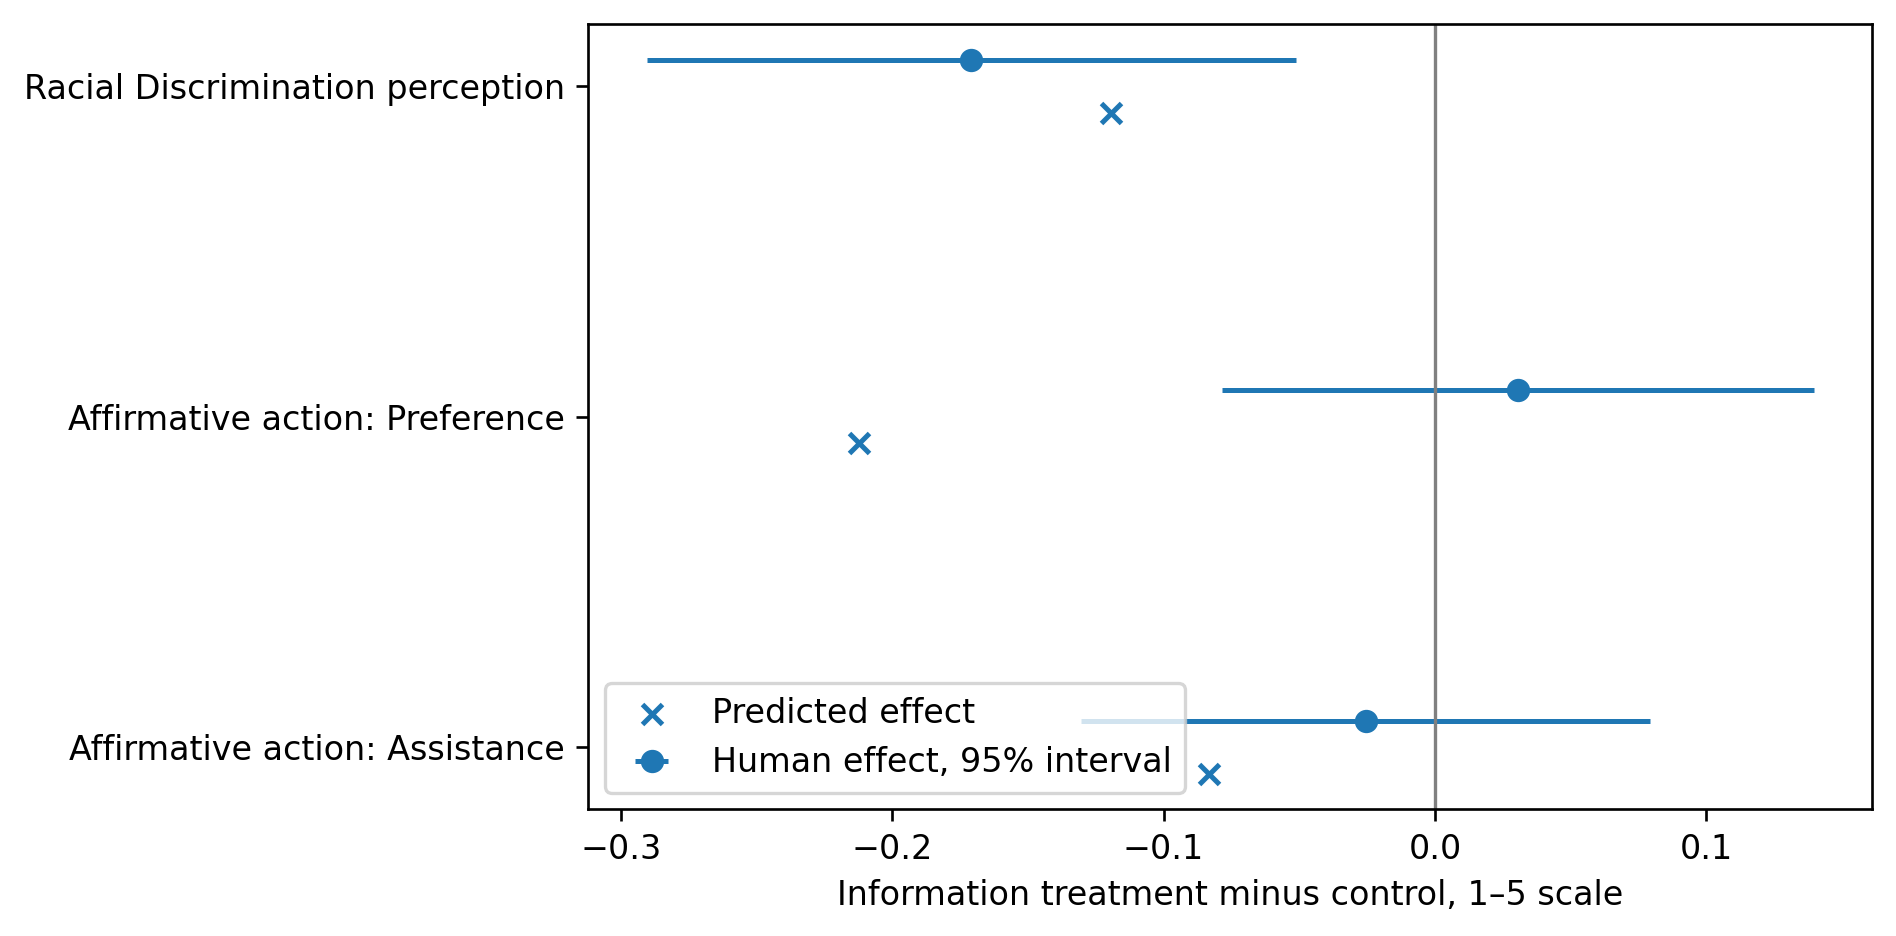

In [29]:
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(summary))
ax.errorbar(summary.human, y + .08, xerr=(summary.upper - summary.lower) / 2,
            fmt="o", label="Human effect, 95% interval")
ax.scatter(summary.model, y - .08, marker="x", label="Predicted effect")
ax.set_yticks(y, summary.outcome)
ax.axvline(0, color="grey", linewidth=1)
ax.set_xlabel("Information treatment minus control, 1–5 scale")
ax.legend()
plt.tight_layout()
plt.show()

**Reading this plot**

- The information treatment lowers perceived seriousness of discrimination by about 0.17 scale points in the human data. The model predicts a smaller decrease, about 0.12 points.
- The human effects on the two policy outcomes are close to zero. The model predicts lower support for both policies. Its clearest discrepancy is hiring preference: roughly −0.21 points, compared with +0.03 in humans.


**Try another comparison**

Choose a study and outcome from `archive_responses.csv.gz`, such as `Haaland874`. List its condition names, then choose two conditions. The cell below recomputes the result from the included response data. How do the treatment effects compare in this study, and the archive more generally?

In [30]:
responses = pd.read_csv(DATA + "archive_responses.csv.gz")
study_id = "Haaland874"
outcome_name = "Racial Discrimination perception"
d = responses[(responses.study == study_id) & (responses.outcome == outcome_name)]
print("Available conditions:", d.condition.unique())

Available conditions: ['TREATMENT' 'CONTROL']
